**Install librarires**

In [13]:
!pip install requests beautifulsoup4 pandas openpyxl matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


**Collect data**

In [2]:
import requests, time
from bs4 import BeautifulSoup
import pandas as pd

books = []
for page in range(1, 6):          # first 5 pages = 100 books
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    r = requests.get(url)
    r.encoding = "utf-8"
    soup = BeautifulSoup(r.text, "html.parser")
    for item in soup.select("article.product_pod"):
        books.append({
            "title": item.h3.a["title"],
            "price": item.select_one("p.price_color").text,
            "rating": item.select_one("p.star-rating")["class"][1],
            "availability": item.select_one("p.availability").text.strip(),
        })
    time.sleep(1)                 # be polite to the server

df = pd.DataFrame(books)
df.head()

,title,price,rating,availability
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


**Clean and organize**

In [8]:
df["price"] = df["price"].astype(str).str.replace("£", "", regex=False).str.replace("Â", "", regex=False).astype(float)

rating_map = {"One":1, "Two":2, "Three":3, "Four":4, "Five":5}
df["rating"] = df["rating"].replace(rating_map).astype(int)

if "availability" in df.columns:
    df["in_stock"] = df["availability"].str.contains("In stock")
    df = df.drop(columns="availability")

df = df.drop_duplicates()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   title     100 non-null    object 
 1   price     100 non-null    float64
 2   rating    100 non-null    int32  
 3   in_stock  100 non-null    bool   
dtypes: bool(1), float64(1), int32(1), object(1)
memory usage: 2.2+ KB


C:\Users\Bhagyshree\AppData\Local\Temp\ipykernel_436\2549051193.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["rating"] = df["rating"].replace(rating_map).astype(int)


**Exploratory analysis**

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df.describe())
print(df.groupby("rating")["price"].agg(["count", "mean"]).round(2))
df.nlargest(5, "price")[["title", "price", "rating"]]

            price      rating
count  100.000000  100.000000
mean    34.560700    2.930000
std     14.638531    1.423149
min     10.160000    1.000000
25%     19.897500    2.000000
50%     34.775000    3.000000
75%     47.967500    4.000000
max     58.110000    5.000000
        count   mean
rating              
1          22  35.52
2          19  35.91
3          22  36.84
4          18  33.98
5          19  30.01


,title,price,rating
68,The Death of Humanity: and the Case for Life,58.11,4
40,Slow States of Collapse: Poems,57.31,3
15,Our Band Could Be Your Life: Scenes from the A...,57.25,3
58,The Past Never Ends,56.50,4
57,The Pioneer Woman Cooks: Dinnertime: Comfort C...,56.41,1


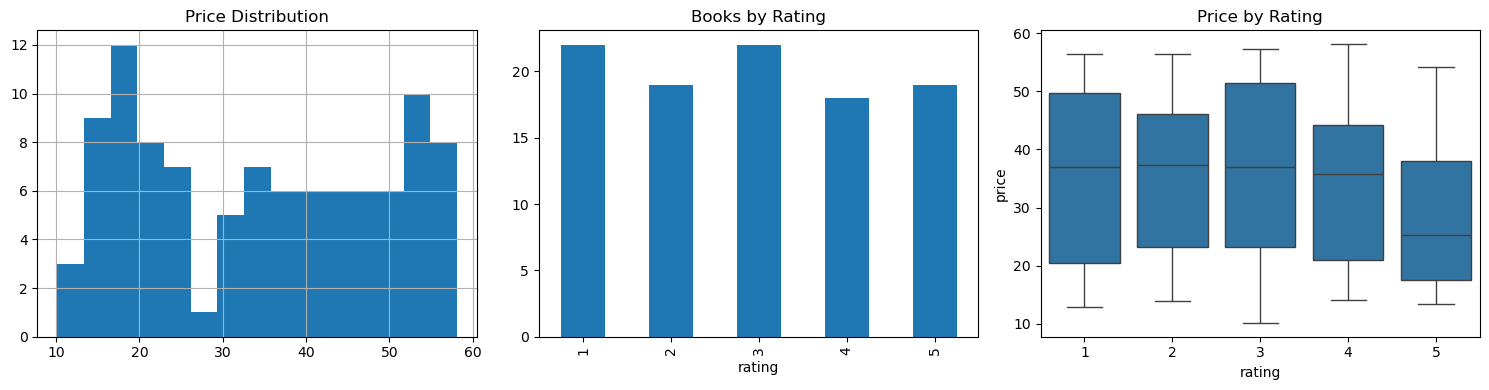

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["price"].hist(bins=15, ax=ax[0]); ax[0].set_title("Price Distribution")
df["rating"].value_counts().sort_index().plot(kind="bar", ax=ax[1], title="Books by Rating")
sns.boxplot(data=df, x="rating", y="price", ax=ax[2]); ax[2].set_title("Price by Rating")
plt.tight_layout()
plt.savefig("books_analysis.png", dpi=150)
plt.show()

**export and automate**

In [13]:
df.to_csv("books_data.csv", index=False)
df.to_excel("books_data.xlsx", index=False)

**Insights**

**1.Price distribution** prices range from about £10 to £60. There are two clusters, one around £15 to £20 and another around £50 to £55, so the catalogue mixes budget and premium books.

**2.Ratings:** books are spread almost evenly across 1 to 5 stars, with 3-star and 1-star books the most common (22 each). Customers' ratings are not skewed toward high scores.

**3.Price vs rating:** median prices are similar (about £35 to £37) for ratings 1 to 4. 5-star books have a lower median price (about £25), which suggests cheaper books tend to be rated higher.

**4.Overall:** price is not a reliable sign of quality here. Expensive books do not earn better ratings.

**5.Stock:** all 100 books are in stock.